# Lab 7 - Go-to-goal: planned, simulated and real trajectories
**Student ID suffix:** 60 | **Experiment:** half-size waypoint coordinates | **Date:** 27 October 2026

This notebook completes the trajectory overlay, waypoint-miss table and logged run-time comparison.
The real run was downloaded from the TRIK robot. A **new matched simulation** uses the real run's
waypoints, controller gains, power limit and goal tolerance; only the wheel geometry changes to the
simulator's dimensions. The older full-size simulator log is not used or scaled artificially.

**Use in Colab:** upload `odometry_data_sim.txt` and `odometry_data_real.txt` when prompted, then run all cells.
Each file has no header and exactly `x_cm,y_cm,time_ms`. The supplied notebook already contains executed outputs.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
required = ['odometry_data_sim.txt', 'odometry_data_real.txt']
if not all((ROOT / name).exists() for name in required):
    from google.colab import files
    files.upload()
assert all((ROOT / name).exists() for name in required), 'Upload both odometry_data files.'
PLOTS = ROOT / 'plots'
PLOTS.mkdir(exist_ok=True)
DATA = ROOT / 'data'
DATA.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})


## Controller, dimensions and half-size waypoints
The implemented nonlinear GTG controller is

`V = K_dist * distance * cos(error)`

`omega = K_angle * error + K_dist * sin(error) * cos(error)`

`error = atan2(sin(course-theta), cos(course-theta))`.

Both runs use **K_dist = 0.6, K_angle = 5, power conversion = 200, maximum power = 70%,
acceptance radius = 10 cm, and a 20 ms requested wait**. The real geometry is r = 4.2 cm,
W = 19.4 cm; simulator geometry is r = 2.8 cm, W = 15.4 cm. These settings were read from
`go_to_goal_real.qrs`, not the stale comment block that still mentions a gain of 30.

All waypoint coordinates are exactly half of the original 60 plan. Each digit is 50 cm wide and
100 cm high, with a 30 cm gap. Point 6 is the transfer destination; point 10 closes the zero and
repeats point 6. The logs use local x along the initial heading and local positive y to the robot's
initial right. Plots reflect x for an upright 60; the same reflection is applied to every dataset.


In [2]:
WP = np.array([
    [0., 0.],
    [50., 0.], [50., -100.], [0., -100.], [0., -50.], [50., -50.],
    [-30., 0.],
    [-80., 0.], [-80., -100.], [-30., -100.], [-30., 0.]
])
GOALS = WP[1:]
EPS_CM = 10.0
PARAMETERS = {
    'k_dist': 0.6, 'k_angle': 5.0, 'power_per_speed': 200.0,
    'max_power_percent': 70.0, 'goal_tolerance_cm': EPS_CM,
    'requested_wait_ms': 20, 'real_r_cm': 4.2, 'real_W_cm': 19.4,
    'sim_r_cm': 2.8, 'sim_W_cm': 15.4
}
sim = np.loadtxt(ROOT / required[0], delimiter=',', ndmin=2)
real = np.loadtxt(ROOT / required[1], delimiter=',', ndmin=2)
for name, a in [('Simulator', sim), ('Real robot', real)]:
    assert a.shape[1] == 3 and len(a) > 1
    assert np.isfinite(a).all() and np.all(np.diff(a[:, 2]) > 0)
    print(f'{name}: {len(a)} samples, first timestamp {a[0,2]:.0f} ms, last {a[-1,2]:.0f} ms')

# Recover waypoint visits from the acceptance rule, using only the required 3-column files.
def visits(a):
    target = 0
    labels = []
    reached = []
    for row in a:
        assert target < len(GOALS), 'Unexpected samples after the final reached goal.'
        labels.append(target)
        if np.linalg.norm(row[:2] - GOALS[target]) <= EPS_CM:
            reached.append(target)
            target += 1
    return np.array(labels), reached

sim_visit, sim_reached = visits(sim)
real_visit, real_reached = visits(real)
assert sim_reached == real_reached == list(range(10)), 'One run did not reach every goal.'
print('Both logs contain all 10 reached goals, including the transfer.')


Simulator: 3329 samples, first timestamp 0 ms, last 66560 ms
Real robot: 430 samples, first timestamp 25 ms, last 25388 ms
Both logs contain all 10 reached goals, including the transfer.


## Planned path versus simulator and real odometry
Solid lines show the digit strokes; dashed lines show transfer goal index 5. The real program
has no physical pen-lift mechanism: this linestyle is an analysis annotation, not a claim that
it lifted a real marker. All plotted positions are encoder odometry estimates.


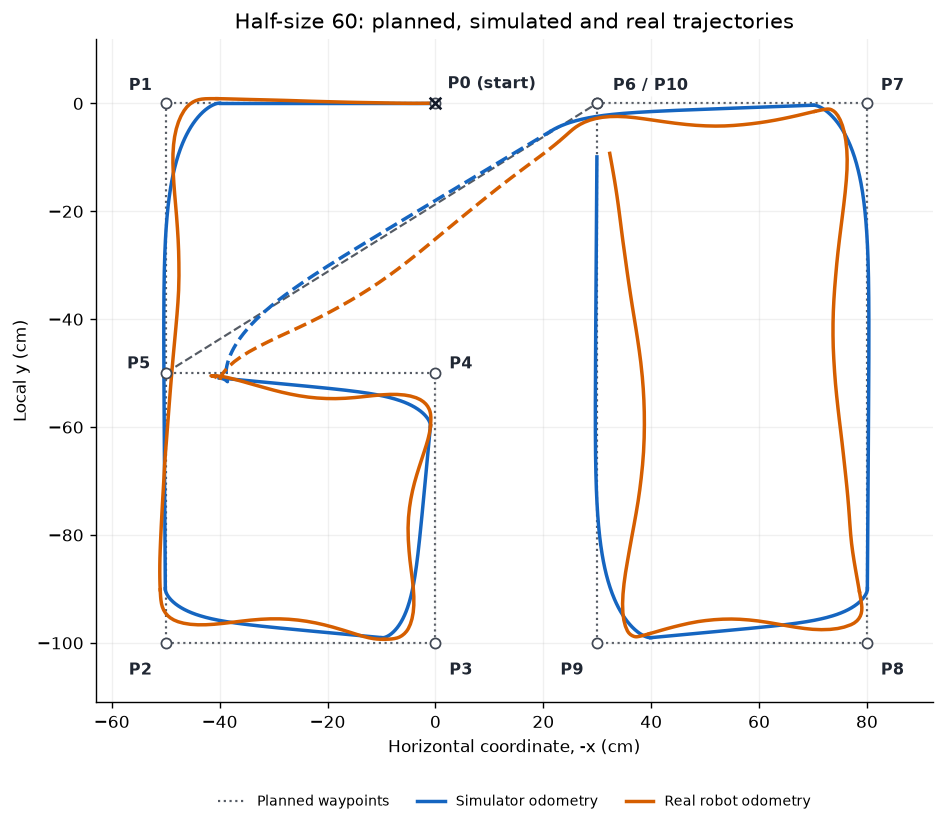

In [3]:
COLORS = {'sim': '#1565c0', 'real': '#d55e00'}
fig, ax = plt.subplots(figsize=(8.4, 6.5), layout='constrained')
for k, (a, b) in enumerate(zip(WP[:-1], WP[1:])):
    ax.plot(-np.array([a[0], b[0]]), [a[1], b[1]], color='#555b64',
            ls='--' if k == 5 else ':', lw=1.25,
            label='Planned waypoints' if k == 0 else None, zorder=1)
ax.scatter(-WP[:,0], WP[:,1], facecolors='white', edgecolors='#414854', s=34, zorder=4)
for a, labels, color, name in [(sim, sim_visit, COLORS['sim'], 'Simulator odometry'),
                                (real, real_visit, COLORS['real'], 'Real robot odometry')]:
    for goal in range(10):
        ix = np.flatnonzero(labels == goal)
        begin = max(0, ix[0] - 1)
        seg = a[begin:ix[-1] + 1]
        ax.plot(-seg[:,0], seg[:,1], color=color, lw=2,
                ls='--' if goal == 5 else '-', label=name if goal == 0 else None, zorder=3)
ax.scatter([0], [0], color='#111827', marker='x', s=45, zorder=5)
# Label planned points with the same numbers used in the waypoint-miss table.
# P6 and P10 share coordinates, so use one combined label instead of overlapping text.
point_groups = {}
for i, point in enumerate(WP):
    point_groups.setdefault(tuple(point), []).append(i)
label_offsets = {
    0: (7, 11, 'left'), 1: (-8, 10, 'right'),
    2: (-8, -16, 'right'), 3: (8, -16, 'left'),
    4: (8, 5, 'left'), 5: (-9, 5, 'right'),
    6: (9, 10, 'left'), 7: (8, 10, 'left'),
    8: (8, -16, 'left'), 9: (-8, -16, 'right')
}
for (x, y), indices in point_groups.items():
    label = ' / '.join(f'P{i}' for i in indices)
    if indices == [0]:
        label += ' (start)'
    dx, dy, ha = label_offsets[indices[0]]
    ax.annotate(label, (-x, y), xytext=(dx, dy), textcoords='offset points',
                ha=ha, va='center', fontsize=9, fontweight='semibold',
                color='#202733', zorder=6,
                bbox=dict(boxstyle='round,pad=0.18', facecolor='white',
                          edgecolor='none', alpha=.9))
ax.margins(x=.09, y=.11)
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=.18)
ax.set_xlabel('Horizontal coordinate, -x (cm)')
ax.set_ylabel('Local y (cm)')
ax.set_title('Half-size 60: planned, simulated and real trajectories')
ax.legend(loc='upper center', bbox_to_anchor=(.5,-.12), ncol=3, frameon=False, fontsize=8)
fig.savefig(PLOTS / 'trajectory_comparison.png', dpi=190, bbox_inches='tight')
plt.show()


## Waypoint-miss table
The course definition is the **minimum sampled distance to each waypoint over the entire run**:
`miss(P) = min(sqrt((x-Px)^2 + (y-Py)^2))`.
Repeated waypoint coordinates therefore have identical global miss values, and later motion may
pass closer to a goal than the sample that triggered the switch. We also calculate a per-visit
miss using only samples assigned to that active goal. This avoids treating a later pass as the
original arrival. Point 0 is the starting point, not an additional controller goal.


Point   x (cm)    y (cm)   Sim miss (cm)   Real miss (cm)
P0        0.0       0.0         0.000            0.000
P1       50.0       0.0         6.331            3.675
P2       50.0    -100.0         7.050            4.465
P3        0.0    -100.0         7.431            5.657
P4        0.0     -50.0         7.429            5.699
P5       50.0     -50.0         0.334            1.477
P6      -30.0       0.0         2.414            2.783
P7      -80.0       0.0         6.527            5.857
P8      -80.0    -100.0         7.036            4.344
P9      -30.0    -100.0         6.808            6.002
P10     -30.0       0.0         2.414            2.783
Largest global miss, excluding start: sim 7.431 cm; real 6.002 cm
Active-goal arrival miss ranges: sim 9.932-9.991 cm; real 9.541-9.854 cm


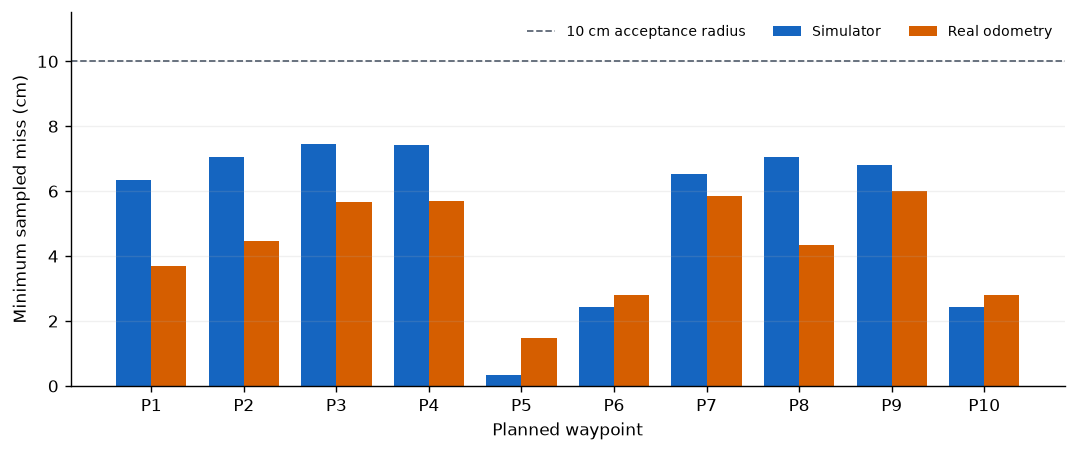

In [4]:
def waypoint_miss(a):
    return np.linalg.norm(a[:,None,:2] - WP[None,:,:], axis=2).min(axis=0)

def active_goal_miss(a, labels):
    return np.array([np.linalg.norm(a[labels == i,:2] - g, axis=1).min()
                     for i, g in enumerate(GOALS)])

miss_sim, miss_real = waypoint_miss(sim), waypoint_miss(real)
active_sim = active_goal_miss(sim, sim_visit)
active_real = active_goal_miss(real, real_visit)
print('Point   x (cm)    y (cm)   Sim miss (cm)   Real miss (cm)')
for i, (wp, ms, mr) in enumerate(zip(WP, miss_sim, miss_real)):
    print(f'P{i:<2d}   {wp[0]:7.1f}   {wp[1]:7.1f}       {ms:7.3f}          {mr:7.3f}')
print(f'Largest global miss, excluding start: sim {miss_sim[1:].max():.3f} cm; real {miss_real[1:].max():.3f} cm')
print(f'Active-goal arrival miss ranges: sim {active_sim.min():.3f}-{active_sim.max():.3f} cm; '
      f'real {active_real.min():.3f}-{active_real.max():.3f} cm')
assert np.all(active_sim <= EPS_CM) and np.all(active_real <= EPS_CM)
miss_export = np.column_stack((np.arange(11), WP, miss_sim, miss_real,
                              np.r_[np.nan,active_sim], np.r_[np.nan,active_real]))
np.savetxt(DATA / 'waypoint_miss.csv', miss_export, delimiter=',', fmt='%.8f',
           header='point,x_cm,y_cm,sim_global_miss_cm,real_global_miss_cm,sim_active_miss_cm,real_active_miss_cm', comments='')
fig, ax = plt.subplots(figsize=(8.5,3.5), layout='constrained')
i = np.arange(1,11)
ax.bar(i-.19, miss_sim[1:], .38, color=COLORS['sim'], label='Simulator')
ax.bar(i+.19, miss_real[1:], .38, color=COLORS['real'], label='Real odometry')
ax.axhline(EPS_CM, color='#56616f', ls='--', lw=1, label='10 cm acceptance radius')
ax.set_xticks(i, [f'P{k}' for k in i]); ax.set_ylim(0,11.5)
ax.set_xlabel('Planned waypoint'); ax.set_ylabel('Minimum sampled miss (cm)')
ax.grid(axis='y', alpha=.18); ax.legend(ncol=3, fontsize=8, frameon=False)
fig.savefig(PLOTS / 'waypoint_miss.png', dpi=190, bbox_inches='tight')
plt.show()


## Logged run times and sampling
Duration is `(last_timestamp - first_timestamp) / 1000`, following the course example. It excludes
unlogged initialization and the final stop/file-write interval. Timestamps are retained as recorded;
no time synchronization, interpolation, decimation or rescaling is applied. The two robots' speed
responses are not calibrated to match, so equal gains and motor-power percentages do not imply
equal velocities or run times.


Simulator: duration 66.560 s; 3329 samples; odometry path 616.73 cm; median interval 20.0 ms
Real robot: duration 25.363 s; 430 samples; odometry path 632.72 cm; median interval 58.0 ms
Simulator/real logged-duration ratio: 2.624


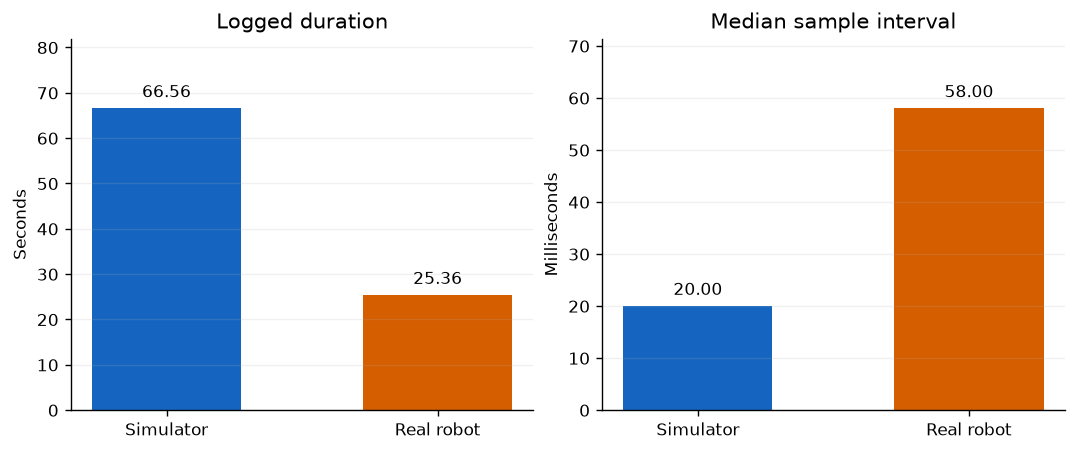

In [5]:
def statistics(a):
    dt = np.diff(a[:,2])
    return {'samples':len(a), 'first_ms':float(a[0,2]), 'last_ms':float(a[-1,2]),
            'duration_s':float((a[-1,2]-a[0,2])/1000),
            'path_length_cm':float(np.linalg.norm(np.diff(a[:,:2],axis=0),axis=1).sum()),
            'median_dt_ms':float(np.median(dt)), 'mean_dt_ms':float(dt.mean()),
            'p95_dt_ms':float(np.percentile(dt,95)), 'max_dt_ms':float(dt.max()),
            'final_position_cm':a[-1,:2].tolist(),
            'final_goal_error_cm':float(np.linalg.norm(a[-1,:2]-GOALS[-1]))}

stats_sim, stats_real = statistics(sim), statistics(real)
for name, st in [('Simulator', stats_sim), ('Real robot', stats_real)]:
    print(f"{name}: duration {st['duration_s']:.3f} s; {st['samples']} samples; "
          f"odometry path {st['path_length_cm']:.2f} cm; median interval {st['median_dt_ms']:.1f} ms")
ratio = stats_sim['duration_s'] / stats_real['duration_s']
print(f'Simulator/real logged-duration ratio: {ratio:.3f}')
fig, axes = plt.subplots(1,2,figsize=(8.5,3.5),layout='constrained')
for ax, vals, title, unit in [
    (axes[0], [stats_sim['duration_s'],stats_real['duration_s']], 'Logged duration', 'Seconds'),
    (axes[1], [stats_sim['median_dt_ms'],stats_real['median_dt_ms']], 'Median sample interval', 'Milliseconds')]:
    bars = ax.bar(['Simulator','Real robot'],vals,color=[COLORS['sim'],COLORS['real']],width=.55)
    ax.bar_label(bars,labels=[f'{v:.2f}' for v in vals],padding=4)
    ax.set_ylim(0,max(vals)*1.23);ax.set_title(title);ax.set_ylabel(unit);ax.grid(axis='y',alpha=.18)
fig.savefig(PLOTS / 'timing_comparison.png',dpi=190,bbox_inches='tight')
plt.show()
summary = {'parameters':PARAMETERS,'waypoints_cm':WP.tolist(),'simulator':stats_sim,'real_robot':stats_real,
           'sim_global_miss_cm':miss_sim.tolist(),'real_global_miss_cm':miss_real.tolist(),
           'sim_active_miss_cm':active_sim.tolist(),'real_active_miss_cm':active_real.tolist(),
           'reached_goal_indices':{'sim':sim_reached,'real':real_reached},
           'comparison':'Matched half-size waypoints and gains; simulator and real geometry differ.',
           'position_basis':'Encoder odometry; physical localization error is not independently measured.'}
(DATA / 'analysis_results.json').write_text(json.dumps(summary,indent=2) + chr(10))


## Discussion and interpretation
Both estimated trajectories round the bottom corners of the 6 (P2-P3) and 0 (P8-P9), with the
largest global miss at P3 for the simulator (7.43 cm) and P9 for the real log (6.00 cm).
The 10 cm acceptance radius is 20% of a digit's width and allows switching before the exact
corner, while the heading gain of 5 permits simultaneous translation and turning.
Active-goal arrival misses of 9.93-9.99 cm in simulation and 9.54-9.85 cm on the robot are
consistent with tolerance-based switching rather than exact waypoint arrival.
The robot's logged duration of 25.363 s versus 66.560 s in simulation is compatible with
different motor-speed responses to the same nominal commands and does not establish better tracking.
The remaining real/model gap may combine motor response, wheel slip and odometry drift;
encoder-only data cannot separate physical control error from localization error.

## Reproducibility and scope
- `go_to_goal_real.qrs` preserves the supplied real project unchanged (originally named `go_to_goal_60_real.qrs`).
- `go_to_goal_sim.qrs` is derived from that project; only geometry, log filename and descriptive comment change.
- `data/nav_data_60_real.csv` preserves the retrieved nine-column robot log; the simulator diagnostic log is also preserved.
- The required TXT files export columns x, y and time only; x/y are converted from metres to centimetres, with every row retained.
- No tape-measured endpoint section is included, as requested.
- [Course Lab 7 instructions](https://github.com/NewUU-engineering/Robotics-course/blob/main/07_Go-to-goal/README.md)
